In [1]:
source('../../../R/preamble.R')

freqplot = function(df, spacing = 0.0){
    ggplot(df) + aes(gen, freq + spacing*dense_rank(pos), col = pos, group = paste0(ref, pos, alt)) + 
    geom_line(linewidth = 0.1) + geom_point(size = 0.3) +
    #scale_x_continuous(breaks = 0:16) +
    facet_wrap(~pop, ncol = 4) +
    labs(x = 'Timepoint', y = 'Frequency')
    }

size(4, 8)
options(repr.matrix.max.cols=150)

muts = 2859179

# Load the raw mutation data

In [2]:
freq_thr = 0.1
singleton_thr = 0.5

raw_vcf = 
    read.tsv('../../../datasets/genomics/01_variant_calling/intermediate/raw_one_indexed.tsv') %>%

    # Add a per-population max freq
    group_by(pos, ref, alt, pop) %>%
    mutate(
        max_f_vcf = max(freq),
        read_pop = pop # backup the original sample name
        ) %>% 
    ungroup()

Now do the removal:

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


... (2 outputs left out)

`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


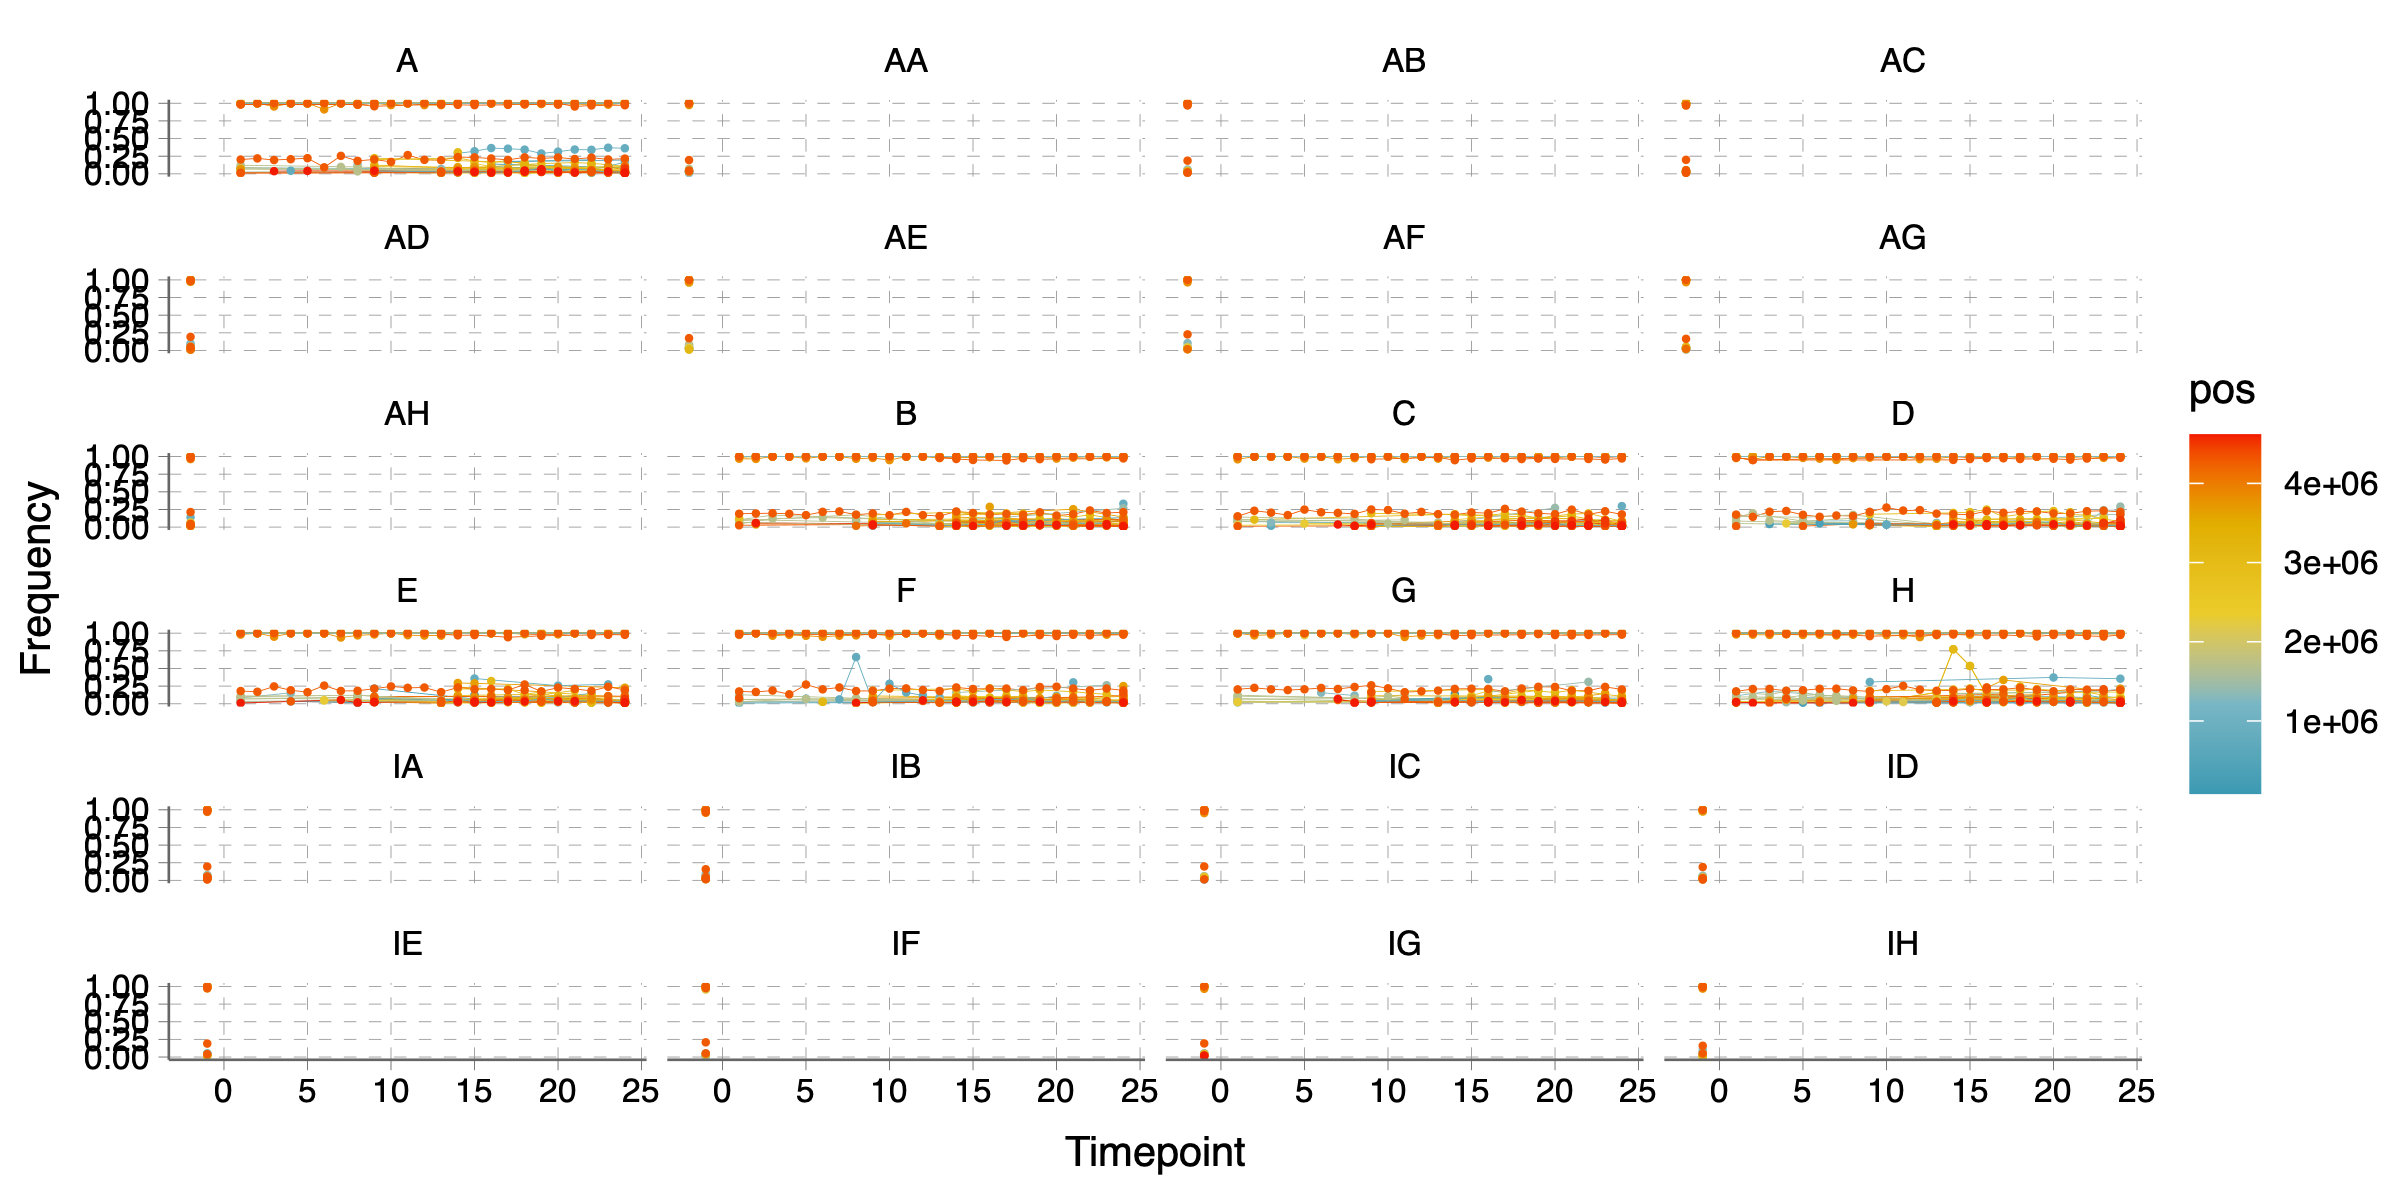

In [3]:
in_wt = (raw_vcf %>% filter(pop == 'W'))$pos

raw_vcf %>% 

    # Artifact hotspots
    filter(
        pop != 'W',
        pos %in% in_wt,
        ) %>% 

freqplot()

In [4]:
raw_no_bg =
raw_vcf %>% 

    # Artifact hotspots
    filter(
        pop != 'W',
        !pos %in% in_wt
        )

In [5]:
write_tsv(raw_no_bg, '../../../datasets/genomics/01_variant_calling/results/raw_no_bg.tsv')